# Classification d’images Fashion-MNIST avec un CNN

## Objectif général

Nous allons construire progressivement un **réseau de neurones convolutif**, ou **CNN** (*Convolutional Neural Network*), capable de reconnaître le type de vêtement représenté sur une image Fashion-MNIST.

Une image sera représentée par une matrice $X$ de taille $28 \times 28$. Chaque nombre de cette matrice indique l’intensité d’un pixel. La réponse attendue est une classe :

$$
y \in \{0,1,\ldots,9\}.
$$

Le travail suivra toujours le même cycle :

1. comprendre et préparer les données ;
2. construire une architecture adaptée ;
3. entraîner le modèle ;
4. évaluer ses performances ;
5. interpréter ses réussites et ses erreurs.

> Dans cette première étape, nous préparons seulement l’environnement. Aucune donnée n’est encore chargée et aucun modèle n’est encore créé.

## Protocole expérimental : éviter la fuite de données

Fashion-MNIST fournit un jeu d’apprentissage officiel et un jeu de test officiel. Plus tard, nous séparerons le jeu d’apprentissage en deux parties disjointes :

$$
D_{\text{apprentissage officiel}} = D_{\text{entraînement}} \cup D_{\text{validation}}.
$$

Le rôle de chaque partie sera différent :

- **entraînement** : calculer et modifier les paramètres du réseau ;
- **validation** : suivre l’apprentissage et choisir les réglages ;
- **test** : mesurer une seule fois la performance finale sur des exemples jamais utilisés pour décider.

Nous imposerons donc notamment :

$$
D_{\text{entraînement}} \cap D_{\text{validation}} = \varnothing
\qquad \text{et} \qquad
D_{\text{test}} \cap D_{\text{entraînement}} = \varnothing
\qquad \text{et} \qquad
D_{\text{test}} \cap D_{\text{validation}} = \varnothing.
$$

Garder le test isolé évite une **fuite de données** : si nous l’utilisions pour choisir le modèle, son score ne représenterait plus honnêtement sa capacité à généraliser.

## 1. Préparer l’environnement et la reproductibilité

L’initialisation des poids, le mélange des images et certaines opérations d’entraînement utilisent des nombres pseudo-aléatoires. Ils sont produits par un algorithme à partir d’une valeur initiale appelée **graine**, ou *seed*.

Nous choisissons ici :

$$
s = 42.
$$

Avec la même graine, le même ordre d’opérations et le même environnement logiciel, nous obtenons généralement les mêmes suites pseudo-aléatoires. Cela facilite la comparaison de deux essais. La graine ne garantit toutefois pas une identité parfaite entre des versions de bibliothèques ou des matériels différents.

`tf.keras.utils.set_random_seed(SEED)` règle ensemble les générateurs de Python, NumPy et TensorFlow. Le mode déterministe demande ensuite à TensorFlow de privilégier des opérations reproductibles ; il peut parfois ralentir les calculs.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

SEED = 42

# Une seule graine pour Python, NumPy et TensorFlow.
tf.keras.utils.set_random_seed(SEED)

# Demande des opérations déterministes lorsque TensorFlow les prend en charge.
tf.config.experimental.enable_op_determinism()

print("TensorFlow :", tf.__version__)
print("NumPy      :", np.__version__)
print("Graine     :", SEED)
print("Environnement prêt.")

TensorFlow : 2.21.0
NumPy      : 2.4.6
Graine     : 42
Environnement prêt.


### Bilan de l’étape

À ce stade :

- les bibliothèques nécessaires au démarrage sont importées ;
- les expériences futures seront plus faciles à reproduire ;
- aucune image n’a encore été chargée ou transformée ;
- le jeu de test n’a pas été consulté.

**Étape suivante :** comprendre comment une image en niveaux de gris devient une matrice de nombres, puis charger Fashion-MNIST.

## 2. Comprendre et charger Fashion-MNIST

### 2.1 Une image en niveaux de gris est une matrice

Une image Fashion-MNIST mesure 28 pixels de hauteur et 28 pixels de largeur. Elle contient donc :

$$
28 \times 28 = 784 \text{ pixels}.
$$

Comme l’image est en niveaux de gris, chaque pixel est représenté par un seul entier. Pour le pixel placé à la ligne $r$ et à la colonne $c$ :

$$
p_{r,c} \in \{0,1,\ldots,255\},
\qquad r,c \in \{0,1,\ldots,27\}.
$$

La valeur 0 représente le noir, 255 le blanc, et les valeurs intermédiaires des nuances de gris. Une image brute $X_i$ est donc une matrice :

$$
X_i \in \{0,\ldots,255\}^{28 \times 28}.
$$

En Python, `images[i, r, c]` désigne le pixel de coordonnées $(r,c)$ dans l’image numéro $i$. Une image est un tableau de rang 2. Un ensemble de $N$ images est un tenseur de rang 3 :

$$
\mathcal{X} \in \{0,\ldots,255\}^{N \times 28 \times 28}.
$$

À chaque image $X_i$ correspond une étiquette entière $y_i$ :

$$
y_i \in \{0,1,\ldots,9\}.
$$

Ces nombres sont seulement des identifiants de catégories : la classe 9 n’est pas « plus grande » que la classe 2.

### 2.2 Charger les données sans les transformer

Keras fournit Fashion-MNIST sous la forme de deux couples :

$$
(X_{\text{train}}, y_{\text{train}})
\qquad \text{et} \qquad
(X_{\text{test}}, y_{\text{test}}).
$$

Nous appelons le premier tableau `images_train_complet_brutes` :

- **train complet** : la partie validation n’a pas encore été extraite ;
- **brutes** : les valeurs sont encore des entiers entre 0 et 255.

Le jeu de test doit être chargé pour être conservé, mais il ne servira ni à choisir l’architecture, ni à régler le modèle, ni à décider quand arrêter l’entraînement. À cette étape, nous ne normalisons rien et nous ne construisons aucun réseau.

In [2]:
(
    (images_train_complet_brutes, etiquettes_train_complet),
    (images_test_brutes, etiquettes_test),
) = tf.keras.datasets.fashion_mnist.load_data()

print("Fashion-MNIST est chargé.")

Fashion-MNIST est chargé.


### 2.3 Vérifier les dimensions et les types

Les dimensions attendues sont :

$$
X_{\text{train}} \in \{0,\ldots,255\}^{60000 \times 28 \times 28},
\qquad
y_{\text{train}} \in \{0,\ldots,9\}^{60000},
$$

$$
X_{\text{test}} \in \{0,\ldots,255\}^{10000 \times 28 \times 28},
\qquad
y_{\text{test}} \in \{0,\ldots,9\}^{10000}.
$$

La première dimension de $X$ doit être égale à la longueur de $y$ : chaque image possède exactement une étiquette.

Les pixels sont stockés avec le type `uint8`, c’est-à-dire un entier non signé sur 8 bits. Huit bits permettent de coder :

$$
2^8 = 256
$$

valeurs différentes, de 0 à 255. Les étiquettes restent des entiers ; nous ne les transformons pas en vecteurs *one-hot*.

In [3]:
print("Images train complètes :", images_train_complet_brutes.shape)
print("Étiquettes train       :", etiquettes_train_complet.shape)
print("Images test            :", images_test_brutes.shape)
print("Étiquettes test        :", etiquettes_test.shape)
print()
print("Type des images       :", images_train_complet_brutes.dtype)
print("Type des étiquettes   :", etiquettes_train_complet.dtype)
print("Pixels du train       :", images_train_complet_brutes.min(), "à", images_train_complet_brutes.max())
print("Classes du train      :", np.unique(etiquettes_train_complet))

assert images_train_complet_brutes.shape == (60_000, 28, 28)
assert etiquettes_train_complet.shape == (60_000,)
assert images_test_brutes.shape == (10_000, 28, 28)
assert etiquettes_test.shape == (10_000,)
assert images_train_complet_brutes.dtype == np.uint8
assert images_test_brutes.dtype == np.uint8
assert np.issubdtype(etiquettes_train_complet.dtype, np.integer)
assert np.issubdtype(etiquettes_test.dtype, np.integer)
assert len(images_train_complet_brutes) == len(etiquettes_train_complet)
assert len(images_test_brutes) == len(etiquettes_test)
assert images_train_complet_brutes.min() == 0
assert images_train_complet_brutes.max() == 255
assert images_test_brutes.min() == 0
assert images_test_brutes.max() == 255
assert np.array_equal(np.unique(etiquettes_train_complet), np.arange(10))
assert np.array_equal(np.unique(etiquettes_test), np.arange(10))

print("\nToutes les vérifications sont réussies.")

Images train complètes : (60000, 28, 28)
Étiquettes train       : (60000,)
Images test            : (10000, 28, 28)
Étiquettes test        : (10000,)

Type des images       : uint8
Type des étiquettes   : uint8
Pixels du train       : 0 à 255
Classes du train      : [0 1 2 3 4 5 6 7 8 9]

Toutes les vérifications sont réussies.


### Bilan de l’étape 2

Nous disposons maintenant de 60 000 images d’apprentissage et de 10 000 images de test. Chaque image brute est une matrice $28 \times 28$ de type `uint8`, et chaque étiquette est un entier compris entre 0 et 9.

Le jeu de test a seulement fait l’objet de contrôles structurels. Il n’a servi à aucune décision. Nous n’avons encore effectué ni normalisation, ni séparation de validation, ni visualisation, ni construction du CNN.

**Étape suivante :** traduire les identifiants 0 à 9 en noms de vêtements et explorer visuellement quelques images du jeu d’apprentissage.

## 3. Associer les classes à des vêtements

### 3.1 Décoder une étiquette

L’étiquette $y_i$ d’une image est un entier entre 0 et 9. Pour la convertir en texte, nous utilisons une table de correspondance $C$ :

$$
\operatorname{nom}(y_i) = C[y_i].
$$

Par exemple, $C[0]$ désigne un T-shirt ou un haut, tandis que $C[9]$ désigne une bottine. Le numéro n’est pas une mesure : il sert uniquement d’adresse dans la table.

| Identifiant | Nom officiel | Traduction française |
|---:|---|---|
| 0 | T-shirt/top | T-shirt / haut |
| 1 | Trouser | Pantalon |
| 2 | Pullover | Pull |
| 3 | Dress | Robe |
| 4 | Coat | Manteau |
| 5 | Sandal | Sandale |
| 6 | Shirt | Chemise |
| 7 | Sneaker | Basket |
| 8 | Bag | Sac |
| 9 | Ankle boot | Bottine |

In [4]:
noms_classes_officiels = np.array(
    [
        "T-shirt/top",
        "Trouser",
        "Pullover",
        "Dress",
        "Coat",
        "Sandal",
        "Shirt",
        "Sneaker",
        "Bag",
        "Ankle boot",
    ]
)

noms_classes_fr = np.array(
    [
        "T-shirt / haut",
        "Pantalon",
        "Pull",
        "Robe",
        "Manteau",
        "Sandale",
        "Chemise",
        "Basket",
        "Sac",
        "Bottine",
    ]
)

assert len(noms_classes_officiels) == 10
assert len(noms_classes_fr) == 10

for identifiant, (nom_officiel, nom_fr) in enumerate(
    zip(noms_classes_officiels, noms_classes_fr)
):
    print(f"{identifiant} : {nom_fr} ({nom_officiel})")

0 : T-shirt / haut (T-shirt/top)
1 : Pantalon (Trouser)
2 : Pull (Pullover)
3 : Robe (Dress)
4 : Manteau (Coat)
5 : Sandale (Sandal)
6 : Chemise (Shirt)
7 : Basket (Sneaker)
8 : Sac (Bag)
9 : Bottine (Ankle boot)


### 3.2 Choisir et afficher une image par classe

Pour chaque classe $k$, nous cherchons uniquement dans le jeu d’apprentissage les indices tels que $y_i=k$. Nous retenons le premier :

$$
i_k = \min \left\{i \in \{0,\ldots,59999\} \mid y_i=k\right\},
\qquad k \in \{0,\ldots,9\}.
$$

L’image affichée pour la classe $k$ sera donc $X_{i_k}$. Cette règle est déterministe : tant que l’ordre du jeu d’apprentissage ne change pas, nous retrouvons les mêmes dix images.

`imshow` convertit visuellement la valeur brute $p$ en une intensité comprise entre 0 et 1 :

$$
g(p)=\frac{p}{255}.
$$

Cette conversion sert seulement à l’affichage : elle ne modifie pas les tableaux. `vmin=0` et `vmax=255` imposent la même échelle de gris aux dix images, et `interpolation="nearest"` laisse visibles les pixels d’origine. Aucune image de test ne sera consultée.

Indices sélectionnés : [1, 16, 5, 3, 19, 8, 18, 6, 23, 0]


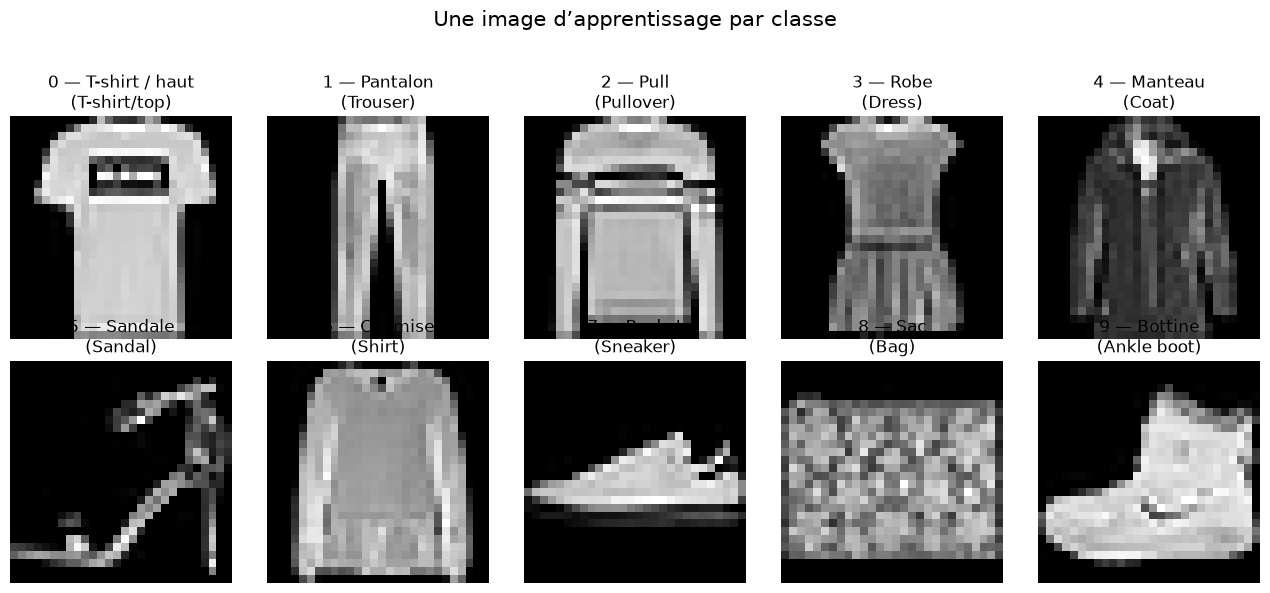

In [5]:
premiers_indices = []

for identifiant in range(10):
    candidats = np.flatnonzero(etiquettes_train_complet == identifiant)
    assert candidats.size > 0
    premiers_indices.append(int(candidats[0]))

assert len(set(premiers_indices)) == 10
assert all(
    etiquettes_train_complet[indice] == identifiant
    for identifiant, indice in enumerate(premiers_indices)
)

print("Indices sélectionnés :", premiers_indices)

figure, axes = plt.subplots(2, 5, figsize=(13, 6))

for identifiant, (axe, indice) in enumerate(
    zip(axes.ravel(), premiers_indices)
):
    axe.imshow(
        images_train_complet_brutes[indice],
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest",
    )
    axe.set_title(
        f"{identifiant} — {noms_classes_fr[identifiant]}\n"
        f"({noms_classes_officiels[identifiant]})"
    )
    axe.axis("off")

figure.suptitle("Une image d’apprentissage par classe", fontsize=15)
figure.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

### Lecture prudente et bilan de l’étape 3

Les images paraissent pixelisées parce qu’elles ne contiennent que $28 \times 28$ pixels. Certaines silhouettes sont visuellement très différentes, comme un sac et une bottine. D’autres catégories de hauts peuvent se ressembler. Il s’agit seulement d’observations descriptives, pas encore d’erreurs du modèle : aucun modèle n’a été entraîné.

Une seule image par classe ne représente pas toute la diversité des vêtements. Cette grille ne permet donc aucune conclusion sur l’accuracy, la généralisation ou la difficulté réelle de chaque classe.

Nous avons exclusivement affiché des images d’apprentissage. Les tableaux sont toujours bruts et le jeu de test reste réservé à l’évaluation finale.

**Étape suivante :** étudier la répartition des classes, puis séparer correctement l’apprentissage et la validation.